# 数値計算演習2：Poisson 方程式と重力

**Ryden, *Celestial and Stellar Dynamics*, §6.4 — 数値計算上の発展**

Notebook 1 では、球対称密度分布から内包質量を数値積分し、
$$
\rho(r)\longrightarrow M(<r)\longrightarrow g_r(r)\longrightarrow v_{\rm circ}(r)
$$
という関係を使いました。

この Notebook では、同じ Plummer 球について Poisson 方程式を解き、
$$
\boxed{
\rho(r)\longrightarrow \Phi(r)\longrightarrow g_r(r)
}
$$
という計算を行います。同じ $g_r(r)$ を2つの方法で求めて比較できることが、数値計算の検証に役立ちます。

Ryden §6.4 で学ぶ球対称密度分布を出発点として、**有限差分法（finite-difference method）**と**数値微分（numerical differentiation）**を学ぶことが目的です。Poisson 方程式の数値解法自体は、§6.4 から発展させた数値計算演習です。

解析解の分かる重力モデルを使い、離散化、境界条件の組み込み、連立一次方程式の構成、数値解の検証を一つずつ学びます。実際の重力計算法は質量分布の表現や計算の目的によって異なり、本演習ではその中から有限差分法による境界値問題の解法を扱います。重力計算法の使い分けは、テキスト付録Bと Notebook B の補足「シミュレーション天文学で使う重力計算法」で紹介します。

この Notebook の補足では、境界条件と陽的・陰的時間積分との関係も紹介しますが、流体の時間発展を実装する演習ではありません。

## 学習目標

1. 球対称 Poisson 方程式を、変数変換 $u=r\Phi$ により有限区間上の1次元境界値問題として設定できる。
2. 二階微分を中心差分で近似し、中心と外側の境界条件を組み込んだ三重対角の連立一次方程式 $A\boldsymbol{u}=\boldsymbol{b}$ を構成できる。
3. 前進差分・後退差分・中心差分を Taylor 展開から導き、数値微分に適用できる。
4. 解析解との比較と格子収束試験から、境界値問題の数値解と数値微分の誤差・収束次数を評価できる。
5. 連立一次方程式の残差と離散化誤差を区別し、残差が小さくても元の微分方程式に対する誤差が残る理由を説明できる。

この Notebook では、本文の学習目標に加えて、総合演習で $\rho\rightarrow\Phi\rightarrow g_r$ の一連の計算を扱い、発展課題で外側境界条件と密度カスプの影響を調べます。末尾には付録Dに対応する数値線形代数の背景も置いています。

### 数値計算法の参考

数値計算法については、幸谷智紀『Python数値計算プログラミング』を参照します。

- 第7章：連立一次方程式の解法
- §12.1–12.2：差分商と中心差分による数値微分
- §14.2：有限差分法による偏微分方程式の数値解法
- §14.2.3：2次元 Poisson 方程式の差分化

この Notebook では線形方程式ソルバーの内部アルゴリズムは本編の対象にせず、付録で補足します。

## 実行順序とテキストとの対応

この Notebook は単独で、上から順に実行できます。モデルのパラメータを変更した場合は、**カーネルを再起動し、変更した設定を保存してから全セルを実行**してください。途中のセルだけを実行すると、初期条件・解析解・加速度に古い値が残る場合があります。

**基本学習は「1. Plummer 球」から「6. 数値微分」までです。** テキスト第2章の§2.1–2.9に対応し、Poisson 方程式の求解と数値微分を、それぞれの格子収束まで学びます。「7. 総合演習：密度 → ポテンシャル → 重力」では、その二つを組み合わせます。第7節の中心近傍の誤差と収束性の補足、第8・9節の境界条件と密度カスプは、基本学習の後に取り組む発展課題です。初読では第6節の演習までで一区切りとし、その後の計算は必要に応じて進めてください。

| テキストの節名 | Notebook 2 の節名 |
| --- | --- |
| Plummer 球の重力を求める二つの方法 | 1. Plummer 球 |
| 球対称 Poisson 方程式の1次元化 | 2. 球対称 Poisson 方程式 |
| Poisson 方程式の中心差分による離散化／中心と外側の境界条件 | 3. 有限差分による離散化 |
| 連立一次方程式の組み立て | 3.1 小さな例：差分式と行列 |
| Plummer 球の Poisson 方程式の数値解 | 4. Poisson 方程式の数値解 |
| Poisson 方程式の格子収束 | 5. Poisson 方程式の格子収束 |
| 数値微分による重力加速度／前進・後退・中心差分の収束比較 | 6. 数値微分 |
| 章末の二つの補足 | 「偏微分方程式の型と境界条件」「時間発展問題の時間積分と連立一次方程式」 |
| 付録D：連立一次方程式の解法 | 付録D：$A\mathbf{x}=\mathbf{b}$ と線形解法 |

小さな配列や1ステップの確認を挟みますが、完成コードは残しています。短い自作部分は新しいセルに書き、続く完成例とは別に実行してください。



# 1. Plummer 球

Notebook 1 と同じ Plummer 密度分布を使います。

$$
\rho(r)=\frac{3M}{4\pi a^3}
\left(1+\frac{r^2}{a^2}\right)^{-5/2}.
$$

無限遠でポテンシャルを0とする基準 $\Phi(\infty)=0$ を使います。この基準での解析的な重力ポテンシャルは
$$
\Phi_{\rm exact}(r)
=
-\frac{GM}{\sqrt{r^2+a^2}},
$$
重力加速度の動径成分は
$$
g_{r,\rm exact}(r)
=
-\frac{d\Phi}{dr}
=
-\frac{GMr}{(r^2+a^2)^{3/2}}.
$$

また、内包質量（enclosed mass）は
$$
M(<r)
=
M\frac{(r/a)^3}{[1+(r/a)^2]^{3/2}}
$$
なので、球対称性から
$$
g_r(r)=-\frac{GM(<r)}{r^2}
$$
としても重力加速度を計算できます。

このように、同じ $g_r(r)$ を複数の方法で求められることを検証に利用します。以下の関数では、`G`, `M`, `a` を省略せず、関数を呼び出すときに指定します。


In [1]:
import numpy as np
import matplotlib.pyplot as plt

G = 1.0
M = 1.0
a = 1.0

OI = {
    "orange": "#E69F00",
    "sky": "#56B4E9",
    "green": "#009E73",
    "yellow": "#F0E442",
    "blue": "#0072B2",
    "vermillion": "#D55E00",
    "purple": "#CC79A7",
    "black": "#000000",
}

plt.rcParams["figure.figsize"] = (6.5, 4.5)
plt.rcParams["font.size"] = 11


In [2]:
def rho_plummer(r, M, a):
    return 3.0 * M / (4.0 * np.pi * a**3) * (1.0 + (r / a)**2)**(-2.5)

def mass_plummer_exact(r, M, a):
    s = r / a
    return M * s**3 / (1.0 + s**2)**1.5

def phi_plummer_exact(r, G, M, a):
    return -G * M / np.sqrt(r**2 + a**2)

def gravity_plummer_exact(r, G, M, a):
    return -G * M * r / (r**2 + a**2)**1.5

def gravity_from_mass(r, menc, G):
    g = np.zeros_like(r, dtype=float)

    # r=0 では -G M(<r)/r^2 が 0/0 になるため、r>0 の要素だけを計算する。
    # mask を使うと、条件を満たす要素だけをまとめて選択できる。
    mask = r > 0.0
    g[mask] = -G * menc[mask] / r[mask]**2
    return g



# 2. 球対称 Poisson 方程式

一般の Poisson 方程式は
$$
\nabla^2\Phi=4\pi G\rho
$$
です。

球対称なら
$$
\frac{1}{r^2}\frac{d}{dr}
\left(
r^2\frac{d\Phi}{dr}
\right)
=
4\pi G\rho(r).
$$

このまま差分化すると $r=0$ の扱いが少し面倒です。そこで
$$
u(r)\equiv r\Phi(r)
$$
と置きます。

すると
$$
\boxed{
\frac{d^2u}{dr^2}=4\pi G r\rho(r)
}
$$
となります。

右辺を
$$
s(r)\equiv4\pi G r\rho(r)
$$
と書けば、
$$
u''(r)=s(r)
$$
という二階微分方程式です。この式の解を定めるには二つの独立な条件が必要です。ここでは中心と外側での値 $u(0)$ と $u(r_{\max})$ を指定します。


**導出：テキスト第2章「球対称 Poisson 方程式の1次元化」。**


# 3. 有限差分による離散化

等間隔格子
$$
r_i=i\Delta r,\qquad \Delta r=r_{\max}/N,\qquad i=0,1,\ldots,N
$$
を使います。

既知の右辺の値を $s_i=s(r_i)$ とし、格子点での未知の数値近似を $u_i$ と書きます。内部格子点で二階微分を中心差分に置き換えると、
$$
\frac{u_{i+1}-2u_i+u_{i-1}}{(\Delta r)^2}
=
s_i.
$$

符号を変えて整理すると、
$$
-u_{i-1}+2u_i-u_{i+1}
=
-(\Delta r)^2s_i.
$$

各格子点の式には $u_{i-1}$, $u_i$, $u_{i+1}$ だけが現れます。このため、差分式全体は三重対角の連立一次方程式
$$
A\mathbf{u}=\mathbf{b}
$$
になります。

## 境界条件

中心では $\Phi(0)$ が有限なので
$$
u(0)=0.
$$

Plummer 球は中心密度が有限で、中心で滑らかな球対称コアを持ちます。中心を通る直線上に、中心を $\ell=0$ とする符号付き座標 $\ell$ を取ると、$r=|\ell|$ です。球対称性から、中心から同じ距離にある2点では
$$
\Phi(\ell)=\Phi(-\ell)
$$
が成り立ち、$\Phi$ は $\ell$ の偶関数です。以下の展開のプライムは $\ell$ に関する微分です。中心で滑らかなら
$$
\begin{aligned}
\Phi(\ell)&=\Phi(0)+\Phi'(0)\ell+\frac12\Phi''(0)\ell^2+\frac1{3!}\Phi'''(0)\ell^3+\cdots,\\
\Phi(-\ell)&=\Phi(0)-\Phi'(0)\ell+\frac12\Phi''(0)\ell^2-\frac1{3!}\Phi'''(0)\ell^3+\cdots.
\end{aligned}
$$
両者が等しいため、奇数次の係数はすべて0になり、
$$
\Phi'(0)=\Phi'''(0)=\cdots=0.
$$
したがって中心近傍では偶数次の項だけが残り、
$$
\Phi(r)=\Phi_0+c_2r^2+c_4r^4+\cdots
$$
と書けます。$r_1=\Delta r$, $r_2=2\Delta r$ とすると
$$
\boxed{
\Phi_0\simeq\frac{4\Phi_1-\Phi_2}{3}
=\frac{8u_1-u_2}{6\Delta r}
}
$$
となります。この式で $\Phi(0)$ を復元します。外挿誤差が $O((\Delta r)^4)$ になるのは、入力する $\Phi_1,\Phi_2$ が厳密値の場合です。入力値に $O((\Delta r)^2)$ の誤差が含まれていれば、それらは一般には相殺されず、中心値にも残ります。外挿公式だけを高次にしても、ポテンシャル全体が4次精度になるわけではありません。

> **重要:** この外挿は、中心でポテンシャルが滑らかで中心の両側で対称になることを仮定しています。Hernquist や NFW のような密度カスプ（density cusp）も球対称ですが、中心での滑らかさが失われます。このため同じ外挿精度は期待できません。後の発展課題で確認します。

外側境界では、まず離散化の精度を検証するため、Plummer モデルの解析解を使って
$$
u(r_{\max})=r_{\max}\Phi_{\rm exact}(r_{\max})
$$
を与えます。

後で、より一般的な遠方境界条件
$$
\Phi(r_{\max})\simeq-\frac{GM}{r_{\max}}
$$
も試します。




格子法の自己重力計算でも、孤立系のポテンシャルを有限領域で解くには境界値が必要です。
質量分布が境界より十分内側に収まる場合には、点質量による項を先頭とし、非球対称な分布の効果を高次の項で表す**多重極展開**を用いることがある（参考：富阪ほか編『シミュレーション天文学』）。
これは質量配置の近似を改良する方法であり、境界より外側の質量を無視したことによる誤差とは区別する。

**導出：テキスト第2章「中心と外側の境界条件」。**



## 3.1 小さな例：差分式と行列

格子点が $r_0,r_1,r_2,r_3,r_4$ の5点なら、未知数は内部の
$$
u_1,\quad u_2,\quad u_3
$$
です。

差分式は
$$
\begin{aligned}
2u_1-u_2 &= -(\Delta r)^2s_1+u_0,\\
-u_1+2u_2-u_3 &= -(\Delta r)^2s_2,\\
-u_2+2u_3 &= -(\Delta r)^2s_3+u_4.
\end{aligned}
$$

したがって
$$
\begin{pmatrix}
2 & -1 & 0\\
-1 & 2 & -1\\
0 & -1 & 2
\end{pmatrix}
\begin{pmatrix}
u_1\\u_2\\u_3
\end{pmatrix}
=
\begin{pmatrix}
-(\Delta r)^2s_1+u_0\\
-(\Delta r)^2s_2\\
-(\Delta r)^2s_3+u_4
\end{pmatrix}.
$$

この Notebook では、連立一次方程式の求解アルゴリズム自体は自作せず、
```python
np.linalg.solve(A, b)
```
を使います。


### 実装確認：3行の連立一次方程式

5格子点 $r_0,\ldots,r_4$ の例を使い、3つの内部点 $u_1,u_2,u_3$ に対する差分式が3行の連立一次方程式になることを確認します。両端の $u_0,u_4$ は境界条件で既知なので、未知数には含めず右辺へ移します。中心の境界値は0なので右辺の最初の要素は変わりませんが、外側の境界値は最後の要素へ加わります。

**自分で書く部分：** `b_small_raw` と2つの境界値から `b_small_student` を作り、`b_small` と一致するか確認してください。続く本編の長い関数でも、右辺に対して行う操作は同じです。

**導出：テキスト第2章「連立一次方程式の組み立て」。**

In [3]:
r_small = np.linspace(0.0, 2.0 * a, 5)
h_small = r_small[1] - r_small[0]
s_small = 4.0 * np.pi * G * r_small * rho_plummer(r_small, M, a)
A_small = np.array([[2.0, -1.0, 0.0], [-1.0, 2.0, -1.0], [0.0, -1.0, 2.0]])
u0_small = 0.0
uN_small = r_small[-1] * phi_plummer_exact(r_small[-1], G, M, a)
b_small_raw = -h_small**2 * s_small[1:-1]
b_small = b_small_raw.copy()
b_small[0] += u0_small
b_small[-1] += uN_small
print("係数行列 A:\n", A_small)
print("境界値を加える前の b:", b_small_raw)
print("境界値を加えた後の b:", b_small)
u_small = np.linalg.solve(A_small, b_small)
np.testing.assert_allclose(A_small @ u_small, b_small, atol=1e-12)

係数行列 A:
 [[ 2. -1.  0.]
 [-1.  2. -1.]
 [ 0. -1.  2.]]
境界値を加える前の b: [-0.21466253 -0.13258252 -0.05908049]
境界値を加えた後の b: [-0.21466253 -0.13258252 -0.95350769]


In [4]:
def solve_spherical_poisson_plummer(N, r_max, G, M, a, boundary="exact"):
    """球対称 Plummer モデルの1次元 Poisson 方程式を有限差分で解く。"""

    if not isinstance(N, (int, np.integer)) or N < 2:
        raise ValueError("N は2以上の整数（区間数）にしてください。")
    if not np.all(np.isfinite([r_max, G, M, a])) or min(r_max, G, M, a) <= 0:
        raise ValueError("r_max, G, M, a は有限な正の値にしてください。")

    # N 区間を N+1 個の格子点で表す。
    r = np.linspace(0.0, r_max, N + 1)
    dr = r[1] - r[0]

    rho = rho_plummer(r, M, a)
    source = 4.0 * np.pi * G * r * rho

    # u=r*Phi の境界値。中心では u(0)=0。
    u0 = 0.0
    if boundary == "exact":
        uN = r_max * phi_plummer_exact(r_max, G, M, a)
    elif boundary == "point_mass":
        uN = -G * M
    else:
        raise ValueError("boundary は 'exact' または 'point_mass' にしてください。")

    # 未知数は内部格子点 u[1], ..., u[N-1] の N-1 個。
    n = N - 1
    A = np.zeros((n, n))

    # 差分式 -u_{i-1} + 2u_i - u_{i+1} = -(dr)^2 s_i
    # に対応する三重対角行列を作る。
    # A[1:] と A[:, 1:] は NumPy の基本スライスによる view なので、
    # そこへの書き込みは元の A に反映される。
    np.fill_diagonal(A, 2.0)          # 主対角
    np.fill_diagonal(A[1:], -1.0)     # 下側の副対角
    np.fill_diagonal(A[:, 1:], -1.0)  # 上側の副対角

    b = -(dr**2) * source[1:N].copy()

    # 差分式に含まれる既知の境界値を右辺へ移項する。
    # 中心では u0=0 なので b[0] += u0 は数値的には値を変えないが、
    # 一般の境界値にも対応できる形として残してある。
    b[0] += u0
    # 外側境界 uN は一般に0ではないため、こちらは実際に右辺を変更する。
    b[-1] += uN

    u = np.zeros(N + 1)
    u[0] = u0
    u[N] = uN
    u[1:N] = np.linalg.solve(A, b)

    # r>0 では Phi=u/r。
    phi = np.empty_like(r)
    phi[1:] = u[1:] / r[1:]

    # 正則な Plummer コアでは Phi'(0)=0 で、
    # Phi(r)=Phi0+c2*r^2+... だから Phi0=(4*Phi1-Phi2)/3 + O(dr^4)。
    phi[0] = (8.0 * u[1] - u[2]) / (6.0 * dr)

    return r, rho, u, phi, A, b

# 4. Poisson 方程式の数値解

まず
$$
r_{\max}=10a,\qquad N=200
$$
で解きます。解析的な外側境界条件を使うので、ここで見えるポテンシャルの誤差は主に有限差分による離散化誤差です。

連立一次方程式の数値解を $A\mathbf{u}=\mathbf{b}$ に代入し、左右のずれも確認します。厳密に満たしていれば差は0です。その差
$$
\mathbf{r}_{\rm res}\equiv A\mathbf{u}-\mathbf{b}
$$
を残差（residual）と呼びます。本文の $\mathbf{u}$ は内部点だけのベクトルですが、配列 `u` は両端の境界値も含むため、`A @ u[1:-1] - b` で計算します。表示する残差は、設定した $G=M=a=1$ の無次元単位での値です。

残差が小さいことは方程式の左右のずれが小さいことを示しますが、それだけで数値解そのものの誤差が小さいとは限りません。連続な Poisson 方程式の解との近さは、解析解との比較や格子収束試験で確認します。


In [5]:
N = 200
r_max = 10.0 * a

r, rho, u, phi_num, A, b = solve_spherical_poisson_plummer(N=N, r_max=r_max, G=G, M=M, a=a, boundary="exact")
phi_exact = phi_plummer_exact(r, G, M, a)

residual = A @ u[1:-1] - b

print(f"格子幅 dr                    = {r[1] - r[0]:.6f}")
print(f"ポテンシャルの最大絶対誤差 = {np.max(np.abs(phi_num - phi_exact)):.6e}")
print(f"連立一次方程式の最大残差   = {np.max(np.abs(residual)):.6e}")


格子幅 dr                    = 0.050000
ポテンシャルの最大絶対誤差 = 6.222636e-04
連立一次方程式の最大残差   = 3.854728e-16


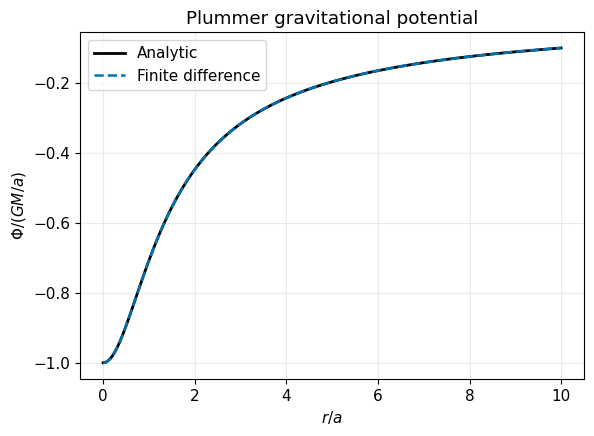

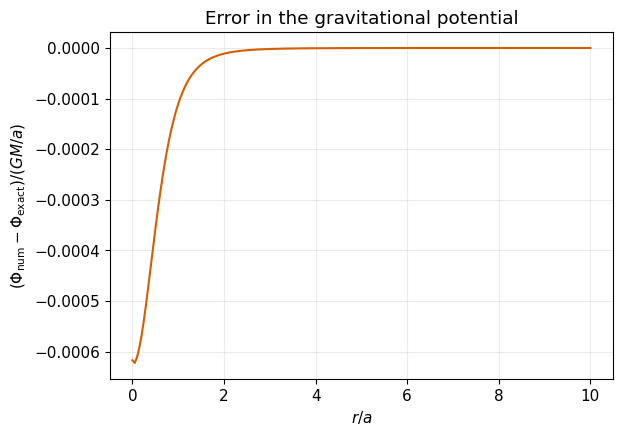

In [6]:
fig, ax = plt.subplots()
ax.plot(r / a, phi_exact / (G * M / a), color=OI["black"], lw=2.0, label="Analytic")
ax.plot(r / a, phi_num / (G * M / a), "--", color=OI["blue"], lw=1.8, label="Finite difference")
ax.set_xlabel(r"$r/a$")
ax.set_ylabel(r"$\Phi/(GM/a)$")
ax.set_title("Plummer gravitational potential")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

fig, ax = plt.subplots()
ax.plot(r / a, (phi_num - phi_exact) / (G * M / a), color=OI["vermillion"])
ax.set_xlabel(r"$r/a$")
ax.set_ylabel(r"$(\Phi_{\rm num}-\Phi_{\rm exact})/(GM/a)$")
ax.set_title("Error in the gravitational potential")
ax.grid(alpha=0.25)
plt.show()



## 演習1：数値解の確認

1. 数値ポテンシャルと解析ポテンシャルがほぼ一致することを確認してください。
2. 誤差が半径によってどのように変化するか説明してください。
3. `N = 50`, `100`, `200`, `400` と変えて結果を比較してください。
4. 連立一次方程式の残差（residual）が非常に小さいことを確認してください。
5. 残差が小さいことと、Poisson 方程式の数値解が解析解に近いことは同じ意味でしょうか。考えてください。


# 5. Poisson 方程式の格子収束

二階中心差分の打ち切り誤差は $O((\Delta r)^2)$ です。ただし、各点での微分の近似誤差と、境界条件を含めて求めたポテンシャル全体の誤差は区別して確認します。

前節の最大絶対誤差を $GM/a$ で割って無次元化した量を
$$
\epsilon_\Phi\equiv\max_{0\le i\le N}\frac{|\Phi_{\rm num}(r_i)-\Phi_{\rm exact}(r_i)|}{GM/a}
$$
とします。外側境界は解析値のまま固定し、格子幅を変えて
$$
\epsilon_\Phi\propto(\Delta r)^p
$$
の $p$ を測ります。$r_{\max}=10a$ に固定し、$N=50,100,200,400,800$ の5格子すべての誤差を両対数で直線近似して、その傾きを求めます。


In [7]:
def poisson_error(N, r_max, G, M, a):
    r, _, _, phi_num, _, _ = solve_spherical_poisson_plummer(N=N, r_max=r_max, G=G, M=M, a=a, boundary="exact")
    phi_exact = phi_plummer_exact(r, G, M, a)
    dr = r[1] - r[0]
    err = np.max(np.abs(phi_num - phi_exact)) / (G * M / a)
    return dr, err

N_values = np.array([50, 100, 200, 400, 800])
dr_values = []
phi_errors = []

for N_i in N_values:
    dr_i, err_i = poisson_error(int(N_i), r_max=10.0 * a, G=G, M=M, a=a)
    dr_values.append(dr_i)
    phi_errors.append(err_i)

dr_values = np.array(dr_values)
phi_errors = np.array(phi_errors)
# 誤差 ε ∝ (dr)^p なら log ε = p log(dr) + 定数。
# np.polyfit(..., 1) の第1要素 [0] が傾き、すなわち収束次数 p。
order_phi = np.polyfit(np.log(dr_values), np.log(phi_errors), 1)[0]

for N_i, dr_i, err_i in zip(N_values, dr_values, phi_errors):
    print(f"N = {N_i:4d}, dr = {dr_i:.6e}, 誤差 = {err_i:.6e}")

print(f"\n測定した収束次数 = {order_phi:.3f}")


N =   50, dr = 2.000000e-01, 誤差 = 9.315659e-03
N =  100, dr = 1.000000e-01, 誤差 = 2.456482e-03
N =  200, dr = 5.000000e-02, 誤差 = 6.222636e-04
N =  400, dr = 2.500000e-02, 誤差 = 1.560776e-04
N =  800, dr = 1.250000e-02, 誤差 = 3.905144e-05

測定した収束次数 = 1.977


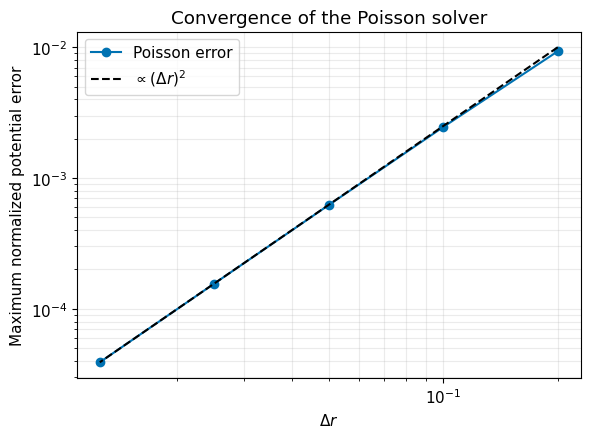

In [8]:
reference = phi_errors[-1] * (dr_values / dr_values[-1])**2

fig, ax = plt.subplots()
ax.loglog(dr_values, phi_errors, "o-", color=OI["blue"], label="Poisson error")
ax.loglog(dr_values, reference, "--", color=OI["black"], label=r"$\propto(\Delta r)^2$")
ax.set_xlabel(r"$\Delta r$")
ax.set_ylabel("Maximum normalized potential error")
ax.set_title("Convergence of the Poisson solver")
ax.legend()
ax.grid(alpha=0.25, which="both")
plt.show()



## 演習2：収束性

1. 測定した収束次数が2に近いことを確認してください。
2. 最も粗い格子を除いて収束次数を再計算してください。
3. `r_max` を変えても、解析的な境界条件を使う限り2次収束が得られるか確認してください。
4. 「差分式を2次精度にした」ことと「数値解全体が2次収束する」ことの関係を説明してください。



# 6. 数値微分

Poisson 方程式から $\Phi(r)$ が得られたら、
$$
g_r(r)=-\frac{d\Phi}{dr}
$$
を計算します。

ポテンシャルが格子上の値として与えられる場合には、差分して重力加速度を求める方法があります（参考：松本ほか『輻射電磁流体シミュレーションの基礎』）。本節では、この計算を題材に数値微分の基本を学びます。

ここでは数値微分の基本として、まず解析的な $\Phi(r)$ を使って差分公式そのものの誤差を調べます。幸谷 §12.1 では、**前進差分・後退差分・中心差分**の3種類がまとめて導入されています。

## 6.1 前進差分

$$
\left.\frac{d\Phi}{dr}\right|_{r_i}
\simeq
\frac{\Phi_{i+1}-\Phi_i}{\Delta r}.
$$

一般に誤差は
$$
O(\Delta r).
$$

## 6.2 後退差分

$$
\left.\frac{d\Phi}{dr}\right|_{r_i}
\simeq
\frac{\Phi_i-\Phi_{i-1}}{\Delta r}.
$$

一般に誤差は
$$
O(\Delta r).
$$

## 6.3 中心差分

$$
\left.\frac{d\Phi}{dr}\right|_{r_i}
\simeq
\frac{\Phi_{i+1}-\Phi_{i-1}}{2\Delta r}.
$$

差分商から厳密な微分値を引いた差の主要項は $(\Delta r)^2\Phi_i'''/6$ です。したがって、一般に誤差は $O((\Delta r)^2)$ です。

したがって、内部格子点では中心差分が高精度です。一方、境界では片側に格子点がないため、

- 左端: 前進差分
- 内部: 中心差分
- 右端: 後退差分

という使い分けが自然です。


## 6.4 中心差分の2次精度

同じ内部格子点 $r_i$ において Taylor 展開すると、
$$
\frac{\Phi_{i+1}-\Phi_i}{\Delta r}=\Phi'_i+\frac{\Delta r}{2}\Phi''_i+O((\Delta r)^2),
$$
$$
\frac{\Phi_i-\Phi_{i-1}}{\Delta r}=\Phi'_i-\frac{\Delta r}{2}\Phi''_i+O((\Delta r)^2)
$$
となります。差分商から厳密な微分値 $\Phi'_i$ を引いた差を考えると、前進差分と後退差分の主要項は、それぞれ $+(\Delta r/2)\Phi''_i$ と $-(\Delta r/2)\Phi''_i$ です。

両者の平均を取ると、1次の誤差が逆符号で相殺され、
$$
\frac12\left[\frac{\Phi_{i+1}-\Phi_i}{\Delta r}+\frac{\Phi_i-\Phi_{i-1}}{\Delta r}\right]=\frac{\Phi_{i+1}-\Phi_{i-1}}{2\Delta r}=\Phi'_i+O((\Delta r)^2)
$$
となります。

前進差分・後退差分・中心差分は独立な3公式ではなく、このような関係を持っています。


**数値誤差の空間的な変化にも注意します。** 各格子点のポテンシャルに大きさ $\delta$ 程度の誤差がばらばらに含まれると、差分で求めた微分に $\delta/\Delta r$ 程度の誤差が現れ得ます。一方、近隣の格子点にほぼ共通する誤差は、差を取ると打ち消し合います。後の総合演習では、ポテンシャルだけでなく重力加速度も約2次で収束することを確認します。

**導出：テキスト第2章「数値微分による重力加速度」。**

In [9]:
def gravity_forward(r, phi):
    """前進差分で g_r=-dPhi/dr を求める。"""
    dr = r[1] - r[0]
    # phi[i+1]-phi[i] を r[i] での微分とみなすので、返す半径は r[:-1]。
    return r[:-1], -(phi[1:] - phi[:-1]) / dr

def gravity_backward(r, phi):
    """後退差分で g_r=-dPhi/dr を求める。"""
    dr = r[1] - r[0]
    # 数値としては前進差分と同じ2点差を使うが、
    # 今度は r[i+1] での微分とみなすので、返す半径は r[1:]。
    return r[1:], -(phi[1:] - phi[:-1]) / dr

def gravity_central(r, phi):
    """中心差分で g_r=-dPhi/dr を求める。"""
    dr = r[1] - r[0]
    # phi[i+1]-phi[i-1] を使うため、両端を除いた r[1:-1] で定義される。
    return r[1:-1], -(phi[2:] - phi[:-2]) / (2.0 * dr)

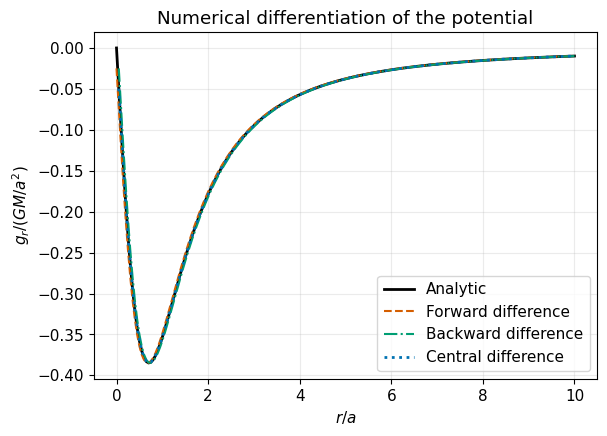

In [10]:
phi_for_diff = phi_plummer_exact(r, G, M, a)

r_f, g_forward = gravity_forward(r, phi_for_diff)
r_b, g_backward = gravity_backward(r, phi_for_diff)
r_c, g_central = gravity_central(r, phi_for_diff)

g_forward_exact = gravity_plummer_exact(r_f, G, M, a)
g_backward_exact = gravity_plummer_exact(r_b, G, M, a)
g_central_exact = gravity_plummer_exact(r_c, G, M, a)

fig, ax = plt.subplots()
ax.plot(r / a, gravity_plummer_exact(r, G, M, a), color=OI["black"], lw=2.0, label="Analytic")
ax.plot(r_f / a, g_forward, "--", color=OI["vermillion"], label="Forward difference")
ax.plot(r_b / a, g_backward, "-.", color=OI["green"], label="Backward difference")
ax.plot(r_c / a, g_central, ":", color=OI["blue"], lw=2.0, label="Central difference")
ax.set_xlabel(r"$r/a$")
ax.set_ylabel(r"$g_r/(GM/a^2)$")
ax.set_title("Numerical differentiation of the potential")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


## 6.5 数値微分の収束

解析的な $\Phi(r)$ を異なる格子幅で評価し、前進・後退・中心差分の収束次数を測ります。Poisson 方程式を数値的に解く誤差を混ぜず、差分公式だけを比較します。

三つの公式を、格子を変えても同じ物理的な半径範囲で比較するため、$0.2a\le r\le5a$ の固定範囲で
$$
\epsilon_{g,\mathrm{fixed}}\equiv\max_{\substack{i\\0.2a\le r_i\le5a}}\frac{|g_{r,\rm num}(r_i)-g_{r,\rm exact}(r_i)|}{GM/a^2}
$$
を測ります。$g_{r,\rm num}$ は各差分公式による重力加速度です。分母は各点の重力加速度ではなく、一定の基準量 $GM/a^2$ なので、これは規格化した絶対誤差です。

$r_{\max}=10a$ に固定し、$N=50,100,200,400,800$ の5格子すべてを両対数の直線近似に使います。有限の格子幅では次の次数の項も寄与するため、前進・後退差分の測定次数はちょうど1にはなりません。この例では、差分商に共通する $(\Delta r)^2\Phi_i'''/6$ の項が前進差分の主要誤差を一部打ち消し、後退差分では加わります。格子を細かくするとこの影響は小さくなり、どちらの測定次数も1へ近づきます。


In [11]:
def differentiation_errors(N, r_max, G, M, a):
    r = np.linspace(0.0, r_max, N + 1)
    phi = phi_plummer_exact(r, G, M, a)
    dr = r[1] - r[0]

    r_f, g_f = gravity_forward(r, phi)
    r_b, g_b = gravity_backward(r, phi)
    r_c, g_c = gravity_central(r, phi)

    # 全格子・全公式で同じ半径範囲 0.2a <= r <= 5a の誤差を比較する。
    # 比較演算を & で結ぶと、条件を同時に満たす要素だけが True になる。
    mask_f = (r_f >= 0.2 * a) & (r_f <= 5.0 * a)
    mask_b = (r_b >= 0.2 * a) & (r_b <= 5.0 * a)
    mask_c = (r_c >= 0.2 * a) & (r_c <= 5.0 * a)

    err_f = np.max(np.abs(g_f[mask_f] - gravity_plummer_exact(r_f[mask_f], G, M, a))) / (G * M / a**2)
    err_b = np.max(np.abs(g_b[mask_b] - gravity_plummer_exact(r_b[mask_b], G, M, a))) / (G * M / a**2)
    err_c = np.max(np.abs(g_c[mask_c] - gravity_plummer_exact(r_c[mask_c], G, M, a))) / (G * M / a**2)
    return dr, err_f, err_b, err_c

N_diff = np.array([50, 100, 200, 400, 800])
dr_diff = []
err_forward = []
err_backward = []
err_central = []

for N_i in N_diff:
    dr_i, ef_i, eb_i, ec_i = differentiation_errors(int(N_i), r_max=10.0 * a, G=G, M=M, a=a)
    dr_diff.append(dr_i)
    err_forward.append(ef_i)
    err_backward.append(eb_i)
    err_central.append(ec_i)

dr_diff = np.array(dr_diff)
err_forward = np.array(err_forward)
err_backward = np.array(err_backward)
err_central = np.array(err_central)

# ε ∝ (dr)^p を仮定し、log-log 空間での直線の傾き p を求める。
# np.polyfit(..., 1)[0] の [0] は1次式の傾き。
order_forward = np.polyfit(np.log(dr_diff), np.log(err_forward), 1)[0]
order_backward = np.polyfit(np.log(dr_diff), np.log(err_backward), 1)[0]
order_central = np.polyfit(np.log(dr_diff), np.log(err_central), 1)[0]

print(f"前進差分の収束次数 = {order_forward:.3f}")
print(f"後退差分の収束次数 = {order_backward:.3f}")
print(f"中心差分の収束次数 = {order_central:.3f}")


前進差分の収束次数 = 0.952
後退差分の収束次数 = 1.030
中心差分の収束次数 = 1.988


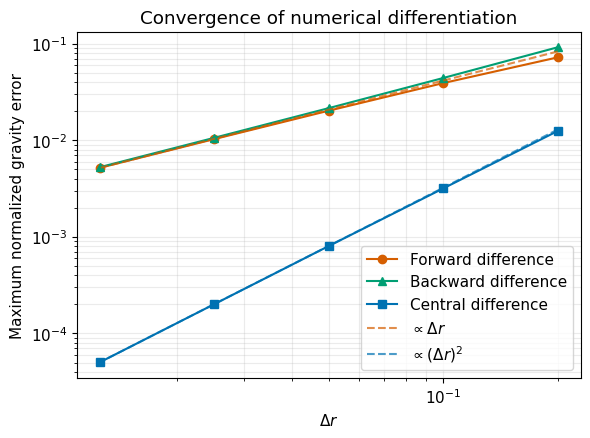

In [12]:
fig, ax = plt.subplots()
ax.loglog(dr_diff, err_forward, "o-", color=OI["vermillion"], label="Forward difference")
ax.loglog(dr_diff, err_backward, "^-", color=OI["green"], label="Backward difference")
ax.loglog(dr_diff, err_central, "s-", color=OI["blue"], label="Central difference")

ax.loglog(dr_diff, err_forward[-1] * (dr_diff / dr_diff[-1]),
          "--", color=OI["vermillion"], alpha=0.7, label=r"$\propto\Delta r$")
ax.loglog(dr_diff, err_central[-1] * (dr_diff / dr_diff[-1])**2,
          "--", color=OI["blue"], alpha=0.7, label=r"$\propto(\Delta r)^2$")

ax.set_xlabel(r"$\Delta r$")
ax.set_ylabel("Maximum normalized gravity error")
ax.set_title("Convergence of numerical differentiation")
ax.legend()
ax.grid(alpha=0.25, which="both")
plt.show()



## 演習3：数値微分

1. 前進差分と後退差分が約1次、中心差分が約2次で収束することを確認してください。
2. Taylor 展開を使い、前進差分と後退差分の主要誤差が同じ大きさで逆符号になることを示してください。
3. 同じ内部格子点で前進差分商と後退差分商から厳密な微分値を引き、符号付き誤差を確認してください。
4. 前進差分商と後退差分商の平均で1次誤差が相殺され、中心差分が2次になる理由を説明してください。
5. 左端・右端・内部で、どの差分公式を使うのが自然か説明してください。
6. 非常に細かい格子では丸め誤差が問題になり得る理由、および数値微分が数値積分よりノイズに敏感な理由を考えてください。


## 補足：偏微分方程式の型と境界条件

この補足と次の時間積分の補足は、将来の宇宙流体計算との関係を示す読み物です。基本学習や後の総合演習を進めるための前提ではありません。

本章で扱った Poisson 方程式は、**楕円型（elliptic）**偏微分方程式の代表例です。
この境界値問題では、内部の方程式と境界条件を合わせ、領域全体で互いに結合した未知数を求める。
本章では中心と外側に条件を与え、有限差分で得た連立一次方程式を解いた。
付録D「連立一次方程式の解法」の反復法を使う場合も、領域全体の方程式を満たす解へ近づける点は同じです。

熱伝導や拡散を記述する**放物型（parabolic）**と、波や移流を記述する**双曲型（hyperbolic）**の方程式も、宇宙流体計算で現れる。
有限領域でこれらの時間発展を求める問題は、初期条件と境界条件を組み合わせた**初期境界値問題（initial-boundary value problem）**として扱う。
正の拡散係数を持つ拡散方程式では、初期分布に加え、空間領域の境界全体で各時刻の条件を定める。
一方、双曲型では情報が有限の速さで伝わる経路を**特性曲線**と呼び、境界で与える独立な条件の数は、領域へ流入する特性の数で決まる。
例えば一定方向に進む移流では、流入側に値を与え、流出側の値は内部から伝わる解によって決まる。
この場合、流出側に独立な値を追加して固定してはいけない。
ただし、流出境界近くの数値更新に必要な値を、内部から外側へ延長する処理は必要になり得る。

本章では既知の境界値を右辺へ移したが、別の実装方法として、計算領域の外側に仮想的な値を置き、境界近傍でも内部と同じ形の更新式を使う方法がある。
格子法の流体計算で用いる**ゴーストセル（ghost cell）**はこの考え方に対応し、付録B「軸対称 Poisson 方程式の数値解法」の対称軸の仮想点とも共通する。
例えば、周期境界では反対側の値をコピーし、反射境界では鏡映した状態の法線方向の速度の符号を反転する。
流出境界では内部の値を外挿する方法があるが、すべての波を無反射で通す保証はない。
必要な物理的条件と、その条件を実装する処理を分けて考えることが重要です。
境界条件とゴーストセルの扱いは、藤井・立川『Pythonで学ぶ流体力学の数値計算法』、松本ほか『輻射電磁流体シミュレーションの基礎』を参照すること。


## 補足：時間発展問題の時間積分と連立一次方程式

時間発展を含む偏微分方程式でも、空間方向を有限差分などで離散化すると、各格子点の値についての連立常微分方程式が得られます。
これを時間方向へ進める方法には、陽的な方法と陰的な方法がある。

既知の状態と、すでに計算した途中の状態から、順に更新量を求める方法を**陽的な時間積分（explicit time integration）**といいます。
第3章で扱う Euler 法と陽的 Runge–Kutta 法では、時間更新の未知量について連立方程式を解く必要はない。
一方、空間離散化と組み合わせた時間刻みの制約を満たす必要がある。
例えば、一次元の圧縮性流体で全セルに共通の時間刻みを使う場合には、
$$
 \Delta t\le C_{\rm CFL}\min_i\frac{\Delta x_i}{|v_i|+c_{{\rm s},i}}
$$
という**CFL 条件（Courant–Friedrichs–Lewy condition）**が重要になる。
$\Delta x_i$ はセル幅、$v_i$ は流速、$c_{{\rm s},i}$ は音速であり、最も厳しいセルの条件を使う。
$C_{\rm CFL}$ の許容値は数値手法に依存し、この条件を満たすだけで任意の空間離散化が安定になるわけではない。
一定の拡散係数を持つ拡散方程式の陽解法では、許される時間刻みの上限は典型的に $\Delta t_{\max}\propto(\Delta x)^2$ となります。
高次精度の公式を選ぶことと、安定に時間発展を計算することは別です。

次の時刻や計算途中の未知の値を含む式を立て、その式を解いて更新する方法を**陰的な時間積分（implicit time integration）**といいます。
線形な問題では連立一次方程式に帰着するが、非線形な問題では非線形方程式を解く必要がある。
例として、本章の $u=r\Phi$ とは区別して拡散する量を $w(x,t)$ と書き、一定の拡散係数 $D>0$ を持つ方程式
$$
 \frac{\partial w}{\partial t}=D\frac{\partial^2 w}{\partial x^2}
$$
を考える。
一様格子上の値を $w_i^n\simeq w(x_i,t_n)$ とし、二階微分を中心差分、時間方向を後退 Euler 法で離散化すると、
$$
 \frac{w_i^{n+1}-w_i^n}{\Delta t}
 =D\frac{w_{i+1}^{n+1}-2w_i^{n+1}+w_{i-1}^{n+1}}{(\Delta x)^2}
$$
です。
これを整理すると、
$$
 -\alpha w_{i-1}^{n+1}+(1+2\alpha)w_i^{n+1}-\alpha w_{i+1}^{n+1}=w_i^n,
 \qquad \alpha=\frac{D\Delta t}{(\Delta x)^2}
$$
となります。
境界値を指定すれば、本章と同じ三重対角構造の連立一次方程式を各ステップで解くことになります。
この線形拡散問題に対する後退 Euler 法では、陽解法の拡散安定条件を避けられるが、大きな時間刻みでも時間変化を正確に追えるという意味ではない。
安定性による制約と、精度のために必要な時間刻みを区別する。

宇宙流体計算では、流体部分を陽的に進め、熱伝導や輻射の拡散など、時間刻みの制約が厳しい過程を陰的に扱うことがある。
また、流体の時間更新が陽的でも、自己重力を求めるには Poisson 方程式を解く。
本章では密度を固定したが、自己重力流体では密度分布が変わるため、時間積分の各段階と整合する密度から重力場を更新する必要がある。
詳しい解法は藤井・立川『Pythonで学ぶ流体力学の数値計算法』、松本ほか『輻射電磁流体シミュレーションの基礎』、自己重力との組合せは富阪ほか編『シミュレーション天文学』を参照すること。



# 7. 総合演習：密度 → ポテンシャル → 重力

ここからは、本文で学んだ Poisson 方程式の求解と数値微分を組み合わせる総合演習です。解析的なポテンシャルではなく、Poisson 方程式から求めた $\Phi_{\rm num}$ を中心差分して重力加速度を求めます。

比較するのは次の3つです。

1. **Poisson 方程式 + 数値微分**
   $$
   \rho\rightarrow\Phi_{\rm num}\rightarrow g_{r,\rm diff}
   $$

2. **数値積分による内包質量**
   $$
   \rho\rightarrow M_{\rm num}(<r)\rightarrow -GM_{\rm num}(<r)/r^2
   $$

3. **解析解**
   $$
   g_{r,\rm exact}
   $$

異なる数値計算法で同じ物理量を求め、互いに比較することが重要です。


内包質量には解析式ではなく Notebook 1 の累積台形則を使います。解析的な重力は両方の経路を検証する基準として別に残します。

誤差の評価では、前節の固定範囲とは別に、中心差分を計算できる内部格子点全体も調べます。Poisson 方程式の数値解を中心差分した結果を $g_{r,\rm diff}$ とし、
$$
\epsilon_g\equiv\max_{1\le i\le N-1}\frac{|g_{r,\rm diff}(r_i)-g_{r,\rm exact}(r_i)|}{GM/a^2}
$$
を測ります。両端 $r_0,r_N$ は含めません。数値質量からの重力にも同じ規格化を使い、内部全域と固定範囲を分けて比較します。

**使う方法：テキスト第2章「Plummer 球の Poisson 方程式の数値解」「数値微分による重力加速度」、第1章「累積積分による内包質量プロファイル」。**

In [13]:
def cumulative_trapezoid_manual(x, y):
    """台形則の累積積分。result[i] は x[0] から x[i] までの積分値。"""
    result = np.zeros_like(x, dtype=float)
    dx = np.diff(x)
    area = 0.5 * (y[:-1] + y[1:]) * dx
    result[1:] = np.cumsum(area)
    return result

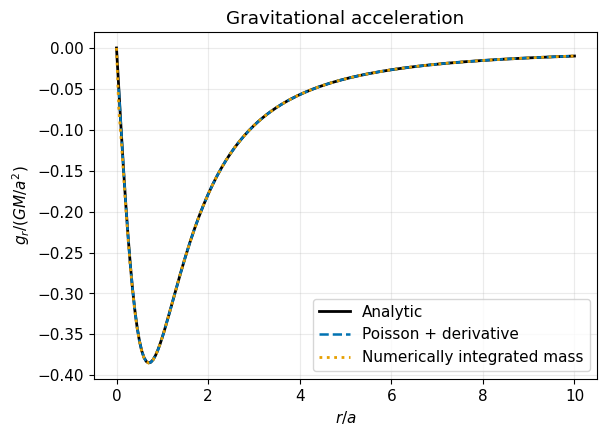

In [14]:
r_g, g_from_phi = gravity_central(r, phi_num)

# Notebook 1 と同じ台形則で密度を積分する。解析的な質量は使わない。
m_num = cumulative_trapezoid_manual(r, 4.0 * np.pi * r**2 * rho)
g_from_m = gravity_from_mass(r, m_num, G)
g_exact = gravity_plummer_exact(r, G, M, a)

fig, ax = plt.subplots()
ax.plot(r / a, g_exact / (G * M / a**2), color=OI["black"], lw=2.0, label="Analytic")
ax.plot(r_g / a, g_from_phi / (G * M / a**2), "--", color=OI["blue"], lw=1.8, label="Poisson + derivative")
ax.plot(r / a, g_from_m / (G * M / a**2), ":", color=OI["orange"], lw=2.0, label="Numerically integrated mass")
ax.set_xlabel(r"$r/a$")
ax.set_ylabel(r"$g_r/(GM/a^2)$")
ax.set_title("Gravitational acceleration")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


In [15]:
g_exact_inner = gravity_plummer_exact(r_g, G, M, a)
err_full = np.max(np.abs(g_from_phi - g_exact_inner)) / (G * M / a**2)

print(f"Poisson 方程式 + 中心差分の最大誤差 = {err_full:.6e}")

# 両経路を同じ固定領域で比較する。中心付近の挙動は別に確認する。
mask_compare = (r_g >= 0.2 * a) & (r_g <= 5.0 * a)
g_mass_inner = g_from_m[1:-1]
err_mass_all = np.max(np.abs(g_mass_inner - g_exact_inner)) / (G * M / a**2)
err_mass_fixed = np.max(np.abs(g_mass_inner[mask_compare] - g_exact_inner[mask_compare])) / (G * M / a**2)
err_phi_fixed = np.max(np.abs(g_from_phi[mask_compare] - g_exact_inner[mask_compare])) / (G * M / a**2)
print(f"数値質量からの重力：内部全域の最大誤差 = {err_mass_all:.6e}")
print(f"固定領域 0.2a <= r <= 5a：Poisson 経路 = {err_phi_fixed:.6e}, 数値質量経路 = {err_mass_fixed:.6e}")


Poisson 方程式 + 中心差分の最大誤差 = 1.663965e-04
数値質量からの重力：内部全域の最大誤差 = 2.472021e-02
固定領域 0.2a <= r <= 5a：Poisson 経路 = 1.663965e-04, 数値質量経路 = 5.126931e-03


## 7.1 発展：誤差の評価範囲と中心近傍の誤差

最初の内部格子点は $r_1=\Delta r$ なので、格子を細かくすると評価する位置自体が中心へ近づきます。Plummer 球の中心付近では $f_M(r)=dM/dr\simeq3Mr^2/a^3$ なので、最初の区間に台形則を使うと、
$$
\begin{aligned}
M_{\rm trap}(<\Delta r)&\simeq\frac{\Delta r}{2}\left[f_M(0)+f_M(\Delta r)\right]=\frac{3M}{2a^3}(\Delta r)^3,\\
M_{\rm exact}(<\Delta r)&\simeq\int_0^{\Delta r}\frac{3M}{a^3}r^2\,dr=\frac{M}{a^3}(\Delta r)^3.
\end{aligned}
$$
この差に $-G/(\Delta r)^2$ を掛けると、重力加速度の誤差は
$$
g_{r,\rm mass}(\Delta r)-g_{r,\rm exact}(\Delta r)=-\frac{GM}{2a^3}\Delta r+O((\Delta r)^3)
$$
となります。この点を含む内部格子点全体の最大誤差には、中心近傍の $O(\Delta r)$ の誤差が効きます。

一方、中心から離れた固定半径では有限の $r^2$ で割るので、台形則の2次の誤差が保たれます。数値質量から求めた重力について、内部全域の最大誤差と、$0.2a\le r\le5a$ の固定範囲の最大誤差を区別します。どちらも $GM/a^2$ で規格化して表示します。



## 7.2 発展：一連の計算の収束と誤差の位置

中心の $\Phi_0$ をポテンシャルの滑らかさから復元したうえで、
$$
\rho\rightarrow\Phi_{\rm num}\rightarrow g_{r,\rm num}
$$
という一連の計算の誤差を調べます。

$N=100$ では最初の内部点 $r_1=\Delta r$ で誤差が最大になります。この実装では、その点の誤差は $O((\Delta r)^3)$ で、中心から離れた領域の $O((\Delta r)^2)$ の誤差より速く減少します。このため、$N\ge200$ では最大誤差の位置が $r\sim a$ 付近へ移ります。全体の収束次数は、誤差が規則的に減少する $N=200,400,800$ の3格子から測ります。

最初の内部点の差分方程式は、$u_0=0$ より
$$
2u_1-u_2=-(\Delta r)^2s_1
$$
です。中心外挿の式と $\Phi_2=u_2/(2\Delta r)$ を中心差分へ代入すると、
$$
g_{r,\mathrm{num}}(r_1)=-\frac{\Phi_2-\Phi_0}{2\Delta r}=\frac{2u_1-u_2}{3(\Delta r)^2}=-\frac{s_1}{3}=-\frac{4\pi G}{3}\Delta r\,\rho(\Delta r)
$$
となります。Plummer の密度と解析的な重力加速度を代入すれば、
$$
\frac{g_{r,\mathrm{num}}(r_1)-g_{r,\mathrm{exact}}(r_1)}{GM/a^2}=\frac{(\Delta r/a)^3}{[1+(\Delta r/a)^2]^{5/2}}
$$
を得ます。この関係は丸め誤差を除いて成り立ち、$\Delta r/a\ll1$ では誤差が $(\Delta r)^3$ に比例します。これは Poisson 方程式の離散化・中心外挿・中心差分を組み合わせた結果であり、差分公式だけの誤差とは区別します。


N =  100, dr = 0.10000, g の最大誤差 = 9.754310e-04, 位置 r/a = 0.100
N =  200, dr = 0.05000, g の最大誤差 = 1.663965e-04, 位置 r/a = 1.050
N =  400, dr = 0.02500, g の最大誤差 = 4.155894e-05, 位置 r/a = 1.025
N =  800, dr = 0.01250, g の最大誤差 = 1.038642e-05, 位置 r/a = 1.038

漸近的な収束次数（最後の3格子） = 2.001


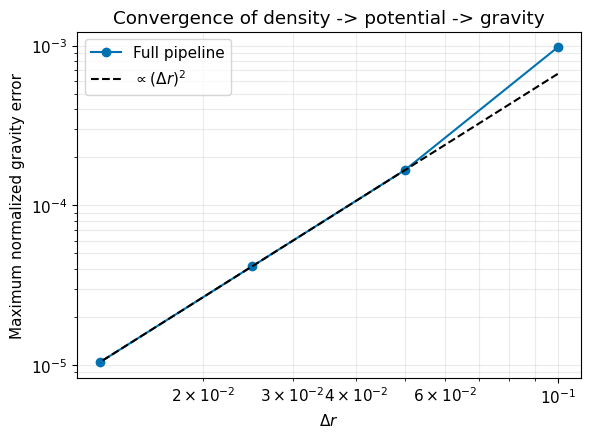

In [16]:
def full_pipeline_gravity_error(N, r_max, G, M, a):
    r, _, _, phi_num, _, _ = solve_spherical_poisson_plummer(
        N=N, r_max=r_max, G=G, M=M, a=a, boundary="exact"
    )
    r_g, g_num = gravity_central(r, phi_num)
    g_ex = gravity_plummer_exact(r_g, G, M, a)
    err = np.abs(g_num - g_ex) / (G * M / a**2)
    return r[1] - r[0], np.max(err), r_g[np.argmax(err)]

N_full = np.array([100, 200, 400, 800])
dr_full, err_full_grid, r_errmax = [], [], []

for N_i in N_full:
    dr_i, err_i, r_i = full_pipeline_gravity_error(int(N_i), r_max=10.0*a, G=G, M=M, a=a)
    dr_full.append(dr_i)
    err_full_grid.append(err_i)
    r_errmax.append(r_i)
    print(f"N = {N_i:4d}, dr = {dr_i:.5f}, g の最大誤差 = {err_i:.6e}, 位置 r/a = {r_i/a:.3f}")

dr_full = np.array(dr_full)
err_full_grid = np.array(err_full_grid)
# 十分細かい格子で漸近領域に入った最後の3点だけを使う。
# log(error) = p log(dr) + 定数 の傾き p を収束次数とする。
order_full = np.polyfit(np.log(dr_full[-3:]), np.log(err_full_grid[-3:]), 1)[0]
print(f"\n漸近的な収束次数（最後の3格子） = {order_full:.3f}")

fig, ax = plt.subplots()
ax.loglog(dr_full, err_full_grid, "o-", color=OI["blue"], label="Full pipeline")
ax.loglog(dr_full, err_full_grid[-1]*(dr_full/dr_full[-1])**2,
          "--", color=OI["black"], label=r"$\propto(\Delta r)^2$")
ax.set_xlabel(r"$\Delta r$")
ax.set_ylabel("Maximum normalized gravity error")
ax.set_title("Convergence of density -> potential -> gravity")
ax.legend()
ax.grid(alpha=0.25, which="both")
plt.show()


In [17]:
mass_full_errors = []
mass_fixed_errors = []
for N_i in N_full:
    r_i = np.linspace(0.0, 10.0 * a, int(N_i) + 1)
    mass_i = cumulative_trapezoid_manual(r_i, 4.0 * np.pi * r_i**2 * rho_plummer(r_i, M, a))
    error_i = np.abs(gravity_from_mass(r_i, mass_i, G) - gravity_plummer_exact(r_i, G, M, a)) / (G * M / a**2)
    fixed_i = (r_i >= 0.2 * a) & (r_i <= 5.0 * a)
    mass_full_errors.append(np.max(error_i))
    mass_fixed_errors.append(np.max(error_i[fixed_i]))
mass_full_errors = np.array(mass_full_errors)
mass_fixed_errors = np.array(mass_fixed_errors)
# log(error) = p log(dr) + 定数。固定領域と全域を別々に当てはめる。
order_mass_full = np.polyfit(np.log(dr_full[-3:]), np.log(mass_full_errors[-3:]), 1)[0]
order_mass_fixed = np.polyfit(np.log(dr_full[-3:]), np.log(mass_fixed_errors[-3:]), 1)[0]
print(f"数値質量経路の次数：全域 = {order_mass_full:.3f}, 固定領域 = {order_mass_fixed:.3f}")

数値質量経路の次数：全域 = 0.992, 固定領域 = 2.001



## 演習4：総合検証

1. 3つの方法で求めた $g_r(r)$ が一致することを確認してください。
2. 一連の計算の収束試験で、十分細かい格子では約2次収束になることを確認してください。
3. 粗い格子では最大誤差の位置が中心近傍にあり、細かくすると $r\sim a$ 付近へ移ることを確認してください。この変化は何を意味するでしょうか。
4. 数値ポテンシャル $\Phi_{\rm num}$ の誤差と、その微分から得た $g_r$ の誤差を比較してください。
5. 「異なる方法で同じ結果を得る」ことが数値的検証として重要な理由を説明してください。


数値質量経路についても、全域最大誤差と固定領域の最大誤差を比較してください。どちらの範囲を使った次数なのかを明記してください。

# 8. 発展課題：境界条件による誤差

外側境界の解析値を点質量近似 $\Phi(r_{\max})=-GM/r_{\max}$ へ変えます。**離散化誤差と境界値の影響は別々に調べます。**

- 格子収束：$r_{\max}$ と境界条件を固定して $N$ を変えます。これは前の収束試験で実施しました。
- 境界値の影響：同じ格子・同じ密度で、点質量境界の数値解から解析境界の数値解を引きます。
- 境界位置の比較：$\Delta r/a$ を固定して $r_{\max}/a$ を変え、それに合わせて $N$ を増やします。

外側境界で与えるポテンシャル値の差を、点質量境界から解析境界を引く順序で
$$
C=-\frac{GM}{r_{\max}}-\Phi_{\rm exact}(r_{\max})=-\frac{GM}{r_{\max}}+\frac{GM}{\sqrt{r_{\max}^2+a^2}}
$$
とします。同じ順序で $u$ の解の差を $\delta u$ とします。二つの解は同じ密度、したがって同じ右辺 $s(r)$ を持つので、方程式を引くと
$$
\delta u''=s(r)-s(r)=0,\qquad \delta u(0)=0,\qquad \delta u(r_{\max})=r_{\max}C
$$
です。$\delta u''=0$ なので差は直線となり、両端の条件から $\delta u(r)=Cr$ です。したがって
$$
\delta\Phi=C,\qquad \delta g_r=-\frac{d\,\delta\Phi}{dr}=0
$$
を得ます。二階中心差分も1次関数を厳密に扱い、中心外挿も定数差を保つので、この性質は離散系でも丸め誤差を除いて成立します。$C$ は固定したポテンシャルのゼロ点に対する定数シフトであり、重力加速度の変化ではありません。

一般の2次元境界誤差は位置に依存し得ます。一方、多次元でも境界全体を**同じ定数だけ**ずらすだけなら定数解が成り立ちます。今回の結果を「どのような境界誤差も重力加速度に影響しない」と一般化しないでください。

遠方で $a^2/r^2\ll1$ として Plummer ポテンシャルを展開すると、
$$
\Phi_{\rm exact}(r)=-\frac{GM}{r}\left(1+\frac{a^2}{r^2}\right)^{-1/2}=-\frac{GM}{r}+\frac{GMa^2}{2r^3}+O(r^{-5})
$$
です。したがって、$r_{\max}\gg a$ では $|C|/(GM/a)\simeq\tfrac12(a/r_{\max})^3$ と小さくなります。

**境界条件の基本：テキスト第2章「中心と外側の境界条件」。境界値差の影響は、この発展課題で上の式を使って調べます。**


予測される定数シフト / (GM/a) = -4.962810e-04
シフトからの最大偏差 / (GM/a) = 3.608e-16
重力の差の最大値 / (GM/a^2) = 1.110e-15


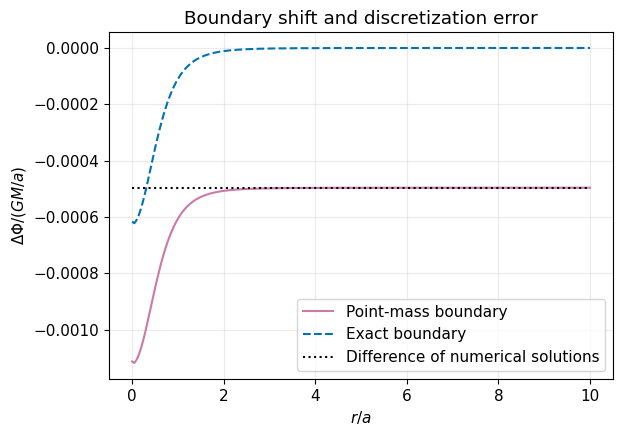

In [18]:
def boundary_comparison(N, r_max, G, M, a):
    """同じ格子・密度で外側境界値だけを変え、解の差を比較する。"""
    r_b, _, _, phi_exbc, _, _ = solve_spherical_poisson_plummer(N=N, r_max=r_max, G=G, M=M, a=a, boundary="exact")
    _, _, _, phi_pmbc, _, _ = solve_spherical_poisson_plummer(N=N, r_max=r_max, G=G, M=M, a=a, boundary="point_mass")
    delta_phi = phi_pmbc - phi_exbc
    _, g_exbc = gravity_central(r_b, phi_exbc)
    _, g_pmbc = gravity_central(r_b, phi_pmbc)
    shift = -G * M / r_max - phi_plummer_exact(r_max, G, M, a)
    return r_b, phi_exbc, phi_pmbc, delta_phi, g_pmbc - g_exbc, shift

r_pm, phi_exbc, phi_pm, delta_phi, delta_g, shift_boundary = boundary_comparison(200, 10.0 * a, G, M, a)
phi_pm_exact = phi_plummer_exact(r_pm, G, M, a)
print(f"予測される定数シフト / (GM/a) = {shift_boundary/(G*M/a):.6e}")
print(f"シフトからの最大偏差 / (GM/a) = {np.max(np.abs(delta_phi-shift_boundary))/(G*M/a):.3e}")
print(f"重力の差の最大値 / (GM/a^2) = {np.max(np.abs(delta_g))/(G*M/a**2):.3e}")

fig, ax = plt.subplots()
ax.plot(r_pm / a, (phi_pm - phi_pm_exact) / (G * M / a), color=OI["purple"], label="Point-mass boundary")
ax.plot(r_pm / a, (phi_exbc - phi_pm_exact) / (G * M / a), "--", color=OI["blue"], label="Exact boundary")
ax.plot(r_pm / a, delta_phi / (G * M / a), ":", color=OI["black"], label="Difference of numerical solutions")
ax.set_xlabel(r"$r/a$")
ax.set_ylabel(r"$\Delta\Phi/(GM/a)$")
ax.set_title("Boundary shift and discretization error")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

### 境界位置の比較：固定した格子幅

$\Delta r/a=0.05$、$r_{\max}/a=5,10,20,40$ とします。区間数は $N=100,200,400,800$ です。単調に小さくなることを確認する対象は、**二つの数値解の差から取り出した境界シフト $|C|$**です。点質量境界で得た解の全誤差が必ず単調減少する、と予想する実験ではありません。

この計算では、解析境界を使ったポテンシャルの誤差と境界値差 $C$ はどちらも負なので、両者が同じ符号で加わります。点質量境界での規格化した最大絶対誤差 $\epsilon_{\Phi,\mathrm{pm}}$ は、$|C|/(GM/a)$ と、同じ格子・同じ領域で解析境界を使った場合の最大誤差との和にほぼ一致します。後者は今回の四つの領域でいずれも約 $6.2\times10^{-4}$ です。符号が異なる場合には相殺も起こり得るので、この加算関係を一般化しないでください。

In [19]:
dr_boundary = 0.05 * a
rmax_boundary = a * np.array([5.0, 10.0, 20.0, 40.0])
boundary_records = []
for outer_r in rmax_boundary:
    n_intervals = int(round(outer_r / dr_boundary))
    rb, pb_exact, pb_mass, dp, dg, C = boundary_comparison(n_intervals, outer_r, G, M, a)
    phi_reference = phi_plummer_exact(rb, G, M, a)
    total_error = np.max(np.abs(pb_mass - phi_reference)) / (G * M / a)
    shift_error = abs(C) / (G * M / a)
    force_change = np.max(np.abs(dg)) / (G * M / a**2)
    boundary_records.append([outer_r/a, n_intervals, shift_error, total_error, force_change])
    print(f"rmax/a={outer_r/a:4.0f}, N={n_intervals:4d}, |C|/(GM/a)={shift_error:.6e}, 全誤差={total_error:.6e}, 重力差={force_change:.2e}")
boundary_records = np.array(boundary_records)

rmax/a=   5, N= 100, |C|/(GM/a)=3.883865e-03, 全誤差=4.505953e-03, 重力差=2.22e-15
rmax/a=  10, N= 200, |C|/(GM/a)=4.962810e-04, 全誤差=1.118545e-03, 重力差=1.11e-15
rmax/a=  20, N= 400, |C|/(GM/a)=6.238306e-05, 全誤差=6.846525e-04, 重力差=2.22e-15
rmax/a=  40, N= 800, |C|/(GM/a)=7.808840e-06, 全誤差=6.300785e-04, 重力差=5.55e-16


## 発展課題

1. 同じ格子で解析境界と点質量境界の解を引き、$\delta\Phi$ が定数になることを確認してください。中心値にも同じシフトが入るでしょうか。
2. 固定した $\Delta r/a$ で境界を遠ざけ、$|C|/(GM/a)$ が減少することを確認してください。$r_{\max}\gg a$ では $|C|/(GM/a)\simeq\tfrac12(a/r_{\max})^3$ です。
3. $N=200$ を固定して同じ境界位置の比較をやり直してください。格子幅の変化により、全誤差が単調には減らない理由を説明してください。
4. ポテンシャルの差と重力加速度の差を区別し、この例の結論を一般の非球対称境界条件へそのまま拡張できない理由を説明してください。


# 9. 発展課題：コアと密度カスプ

中心外挿
$$
\Phi_0\simeq\frac{4\Phi_1-\Phi_2}{3}
$$
は、Plummer のように中心で滑らかなコアで
$$
\Phi(r)=\Phi_0+c_2r^2+c_4r^4+\cdots
$$
と展開できることを使っています。

Notebook 1 で扱った Hernquist 分布では
$$
\rho(r)=\frac{Ma}{2\pi r(r+a)^3},
\qquad
\Phi(r)=-\frac{GM}{r+a}.
$$

Hernquist 分布も球対称ですが、直線上のポテンシャルは
$$
\Phi_{\rm H}(r=|\ell|)=-\frac{GM}{a+|\ell|}
$$
となります。これは偶関数でも、中心で左右からの傾きが一致せず、滑らかに微分できません。失われるのは球対称性ではなく中心での滑らかさなので、Plummer 球で使った滑らかな偶関数の Taylor 展開は適用できません。

中心では密度カスプ（density cusp）$\rho\propto r^{-1}$ を持ち、ポテンシャルは
$$
\Phi(r)
=
-\frac{GM}{a}
+
\frac{GM}{a^2}r
+O(r^2)
$$
と **1次項を持ちます**。一般に $\Phi(r)=\Phi_0+c_1r+c_2r^2+\cdots$ を中心外挿に代入すると、
$$
\frac{4\Phi(\Delta r)-\Phi(2\Delta r)}{3}=\Phi_0+\frac23c_1\Delta r+O((\Delta r)^3)
$$
となります。$c_2$ の項は消えますが、1次の項は残ります。Hernquist ポテンシャルでは $c_1=GM/a^2$ なので、
$$
\Phi_{0,\rm ext}-\Phi_0
\simeq
\frac{2}{3}\frac{GM}{a^2}\Delta r
$$
となり、中心値は1次精度に低下します。

上の誤差評価は厳密な関数値を外挿した場合のものです。続くコードでは、Hernquist の密度から Poisson 方程式を有限差分で解き、その数値解へ同じ外挿を適用します。

密度は中心で発散しますが、右辺は $r>0$ で
$$
s(r)=4\pi Gr\rho_{\rm H}(r)=\frac{2GMa}{(r+a)^3}
$$
と整理でき、中心でも有限な極限を持ちます。第1章の質量の被積分関数と同じく、中心で密度を直接評価せず、この整理した式で右辺を計算します。

ここでは $r_{\max}=20a$ に固定し、外側境界には解析値を与えるため、遠方近似による境界値の誤差は含めません。中心値の絶対誤差を $GM/a$ で割って測ります。測定値には、外挿の誤差に加えて求解時の離散化誤差も含まれます。

**中心外挿の基本：テキスト第2章「中心と外側の境界条件」。その適用範囲を、この発展課題で調べます。**


N =   50, dr = 0.40000, |Phi0_ext-Phi0| = 2.739096e-01
N =  100, dr = 0.20000, |Phi0_ext-Phi0| = 1.413508e-01
N =  200, dr = 0.10000, |Phi0_ext-Phi0| = 6.988985e-02
N =  400, dr = 0.05000, |Phi0_ext-Phi0| = 3.433295e-02

密度カスプで測定した収束次数 = 1.000


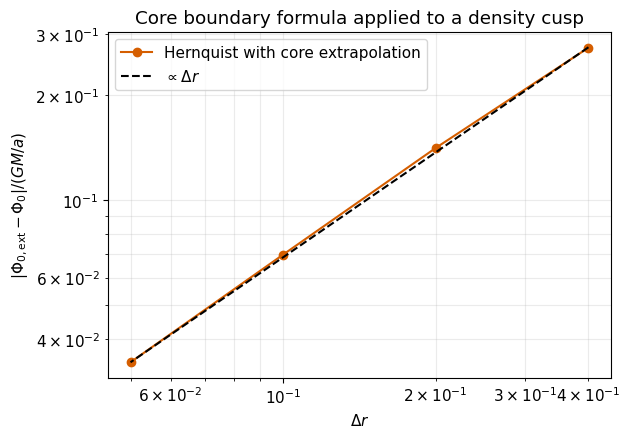

In [20]:
def phi_hernquist_exact(r, G, M, a):
    return -G * M / (r + a)

def hernquist_phi0_error(N, r_max, G, M, a):
    r = np.linspace(0.0, r_max, N + 1)
    dr = r[1] - r[0]

    # Hernquist では 4*pi*G*r*rho = 2*G*M*a/(r+a)^3 で、r=0 でも有限。
    source = 2.0 * G * M * a / (r + a)**3
    n = N - 1
    A = np.zeros((n, n))
    np.fill_diagonal(A, 2.0)
    np.fill_diagonal(A[1:], -1.0)
    np.fill_diagonal(A[:, 1:], -1.0)

    u0 = 0.0
    uN = r_max * phi_hernquist_exact(r_max, G, M, a)
    b = -(dr**2) * source[1:N].copy()
    b[0] += u0
    b[-1] += uN

    u = np.zeros(N + 1)
    u[-1] = uN
    u[1:N] = np.linalg.solve(A, b)

    # Hernquist はカスプを持つが、比較のため Plummer 用のコア外挿をあえて適用する。
    phi0_ext = (8.0*u[1] - u[2]) / (6.0*dr)
    err = abs(phi0_ext - phi_hernquist_exact(0.0, G, M, a)) / (G * M / a)
    return dr, err

N_cusp = np.array([50, 100, 200, 400])
dr_cusp, err_cusp = [], []
for N_i in N_cusp:
    dr_i, err_i = hernquist_phi0_error(int(N_i), r_max=20.0*a, G=G, M=M, a=a)
    dr_cusp.append(dr_i)
    err_cusp.append(err_i)
    print(f"N = {N_i:4d}, dr = {dr_i:.5f}, |Phi0_ext-Phi0| = {err_i:.6e}")

dr_cusp = np.array(dr_cusp)
err_cusp = np.array(err_cusp)
# ε ∝ (dr)^p を log-log 空間で直線近似し、その傾き p を測る。
# np.polyfit(..., 1)[0] の [0] が傾き。
order_cusp = np.polyfit(np.log(dr_cusp), np.log(err_cusp), 1)[0]
print(f"\n密度カスプで測定した収束次数 = {order_cusp:.3f}")

fig, ax = plt.subplots()
ax.loglog(dr_cusp, err_cusp, "o-", color=OI["vermillion"], label="Hernquist with core extrapolation")
ax.loglog(dr_cusp, err_cusp[-1]*(dr_cusp/dr_cusp[-1]),
          "--", color=OI["black"], label=r"$\propto\Delta r$")
ax.set_xlabel(r"$\Delta r$")
ax.set_ylabel(r"$|\Phi_{0,\rm ext}-\Phi_0|/(GM/a)$")
ax.set_title("Core boundary formula applied to a density cusp")
ax.legend()
ax.grid(alpha=0.25, which="both")
plt.show()



## 発展課題：収束次数の低下

1. Hernquist ポテンシャルを $r=0$ のまわりで Taylor 展開し、1次項が存在することを確認してください。
2. $\Phi_{0,\rm ext}=(4\Phi_1-\Phi_2)/3$ にその展開を代入し、主要誤差が $O(\Delta r)$ になることを示してください。
3. 数値計算から収束次数が約1になることを確認してください。
4. NFW 分布についても中心ポテンシャルの展開を調べ、同じ滑らかなコアに対する式を使えるか考えてください。
5. 「高次の差分公式を選ぶ」だけでなく「境界条件の物理的仮定を確認する」ことが必要な理由を説明してください。


# 付録D：連立一次方程式の解法

連立一次方程式の直接法については、幸谷 第7章を参考にします。

本編では
```python
x = np.linalg.solve(A, b)
```
を使いました。

この Notebook の目的は Poisson 方程式の離散化なので、連立一次方程式のソルバーは Python のライブラリに任せます。ただし、その背景には次のような数値線形代数があります。

## D.1 Gauss 消去法（Gaussian elimination）

連立一次方程式から未知数を順に消去し、上三角行列を作ります。その後、後退代入（back substitution）で解を求めます。

## D.2 LU 分解（LU decomposition）

係数行列を
$$
A=LU
$$
と分解し、
$$
L\mathbf{y}=\mathbf{b},\qquad
U\mathbf{x}=\mathbf{y}
$$
を順番に解きます。

## D.3 三重対角連立方程式（tridiagonal system）

今回の1次元 Poisson 方程式の係数行列は三重対角です。その構造を利用すると、Thomas 法（Thomas algorithm）により $O(N)$ の計算量で解けます。

本演習ではソルバーを自作する必要はありません。余裕がある場合に、Gauss 消去法や Thomas 法を別の補足課題として学習してください。

## D.4 残差

ライブラリのソルバーを使った場合でも、
$$
\mathbf{r}_{\rm res}=A\mathbf{x}-\mathbf{b}
$$
を計算して残差が小さいことを確認できます。

残差は、数値解を代入したときの方程式の左右のずれです。残差が小さいことだけで、数値解そのものの誤差や、連続な Poisson 方程式の解からの誤差が小さいとは限りません。後者は格子収束試験や解析解との比較で確認します。


# まとめ

この Notebook では、
$$
\boxed{
\rho(r)
\longrightarrow
\Phi(r)
\longrightarrow
g_r(r)
}
$$
という流れを数値計算しました。

学んだ数値計算法は、

- 有限差分による離散化
- 2次精度の中心差分
- 境界条件
- 連立一次方程式 $A\mathbf{u}=\mathbf{b}$
- `numpy.linalg.solve`
- 残差の確認
- 前進差分
- 後退差分
- 中心差分
- 格子収束試験
- 滑らかなコアに対する中心境界処理と、密度カスプへの適用限界

です。

Ryden 第6章に対応する Notebook 1 と Notebook 2 を合わせると、
$$
\boxed{
\rho(r)
\longrightarrow
M(<r),\ \Phi(r)
\longrightarrow
g_r(r),\ v_{\rm circ}(r)
}
$$
までを数値的に求めたことになります。

次の Notebook 3 では、同じ Plummer 球の解析的な重力加速度を使って軌道を計算し、時間積分法を学びます。軸対称 Poisson 方程式は Notebook B、指数円盤の質量積分は付録Aと Notebook A にまとめています。これらは軌道計算へ進むための前提ではありません。
